In [1]:
# What's in the dictionary

import pickle
from pathlib import Path
import numpy as np

with open(Path("raw/wisig_manysig/ManySig.pkl"), "rb") as f:
    ds = pickle.load(f)

print(ds.keys())
for k in ["tx_list", "rx_list", "capture_date_list", "equalized_list", "max_sig"]:
    print(k, "=", ds[k])

dict_keys(['tx_list', 'rx_list', 'capture_date_list', 'equalized_list', 'max_sig', 'data'])
tx_list = ['14-10', '14-7', '20-15', '20-19', '6-15', '8-20']
rx_list = ['1-1', '1-19', '14-7', '18-2', '19-2', '2-1', '2-19', '20-1', '3-19', '7-14', '7-7', '8-8']
capture_date_list = ['2021_03_01', '2021_03_08', '2021_03_15', '2021_03_23']
equalized_list = [0, 1]
max_sig = 1000


In [2]:
# How many signals per tx, rx, day, version; and the number type (float 32, 64)

leaf = ds["data"][0][0][0][0]          # tx 0, rx 0, day 0, version 0
print(type(leaf), leaf.shape, leaf.dtype)

counts = np.array([[[[len(ds["data"][t][r][d][e])
                      for e in range(len(ds["equalized_list"]))]
                     for d in range(len(ds["capture_date_list"]))]
                    for r in range(len(ds["rx_list"]))]
                   for t in range(len(ds["tx_list"]))])
print("counts shape (tx, rx, day, eq):", counts.shape)
print("min / max per cell:", counts.min(), counts.max(), "| total:", counts.sum())

<class 'numpy.ndarray'> (1000, 256, 2) float64
counts shape (tx, rx, day, eq): (6, 12, 4, 2)
min / max per cell: 1000 1000 | total: 576000


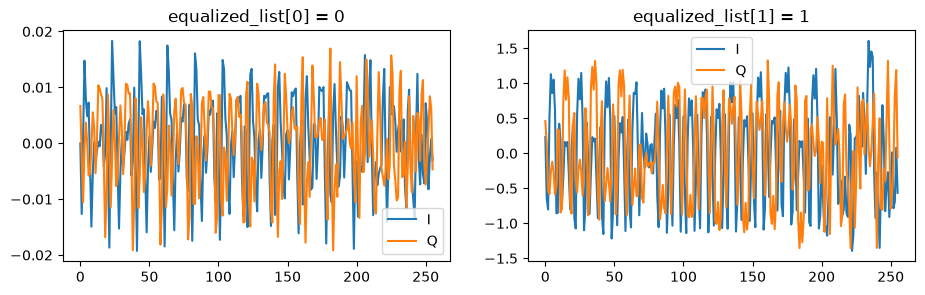

In [3]:
# Shows the actual signals

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for e, ax in enumerate(axes):
    sig = ds["data"][0][0][0][e][0]    # tx 0, rx 0, day 0, version e, signal 0
    ax.plot(sig[:, 0], label="I")
    ax.plot(sig[:, 1], label="Q")
    ax.set_title(f"equalized_list[{e}] = {ds['equalized_list'][e]}")
    ax.legend()
plt.show()


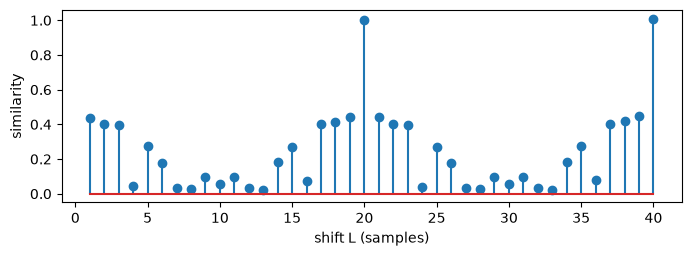

most similar after shifting by 40 samples


In [4]:
# Sampling rate: after how many samples does the short preamble repeat?

sigs = ds["data"][0][0][0][0][:100]          # 100 signals, non-equalized
x = sigs[:, :, 0] + 1j * sigs[:, :, 1]        # I and Q as complex numbers: shape (100, 256)
seg = x[:, :150]                              # the first 150 samples, inside the short preamble

lags = np.arange(1, 41)
sim = []
for L in lags:
    a, b = seg[:, :-L], seg[:, L:]            # the signal, and the same signal shifted by L
    sim.append(np.mean(np.abs(np.sum(np.conj(a) * b, axis=1)) / np.sum(np.abs(a) ** 2, axis=1)))

plt.figure(figsize=(8, 2.5))
plt.stem(lags, sim)
plt.xlabel("shift L (samples)")
plt.ylabel("similarity")
plt.show()
print("most similar after shifting by", lags[np.argmax(sim)], "samples")

## Findings

Paper = our first submission (arXiv 2511.07026). Old code = `sensorlab/ZeroUED` on GitHub.

### About the file
- ManySig is a small ready-made subset of WiSig.
  - Full WiSig: 174 transmitters, 41 receivers, 4 days over a month, about 10 million packets.
  - ManySig: 6 transmitters, 12 receivers, 4 days.
- Transmitters: 14-10, 14-7, 20-15, 20-19, 6-15, 8-20.
- Receivers: 1-1, 1-19, 14-7, 18-2, 19-2, 2-1, 2-19, 20-1, 3-19, 7-14, 7-7, 8-8.
- The names are positions in the ORBIT testbed grid (20 × 20 nodes, about 1 m apart). Node 1-1 is one receiver (a USRP N210) in a corner.
- Days: 2021-03-01, 03-08, 03-15, 03-23, about a week apart.
- Two versions per signal: `equalized_list = [0, 1]`, so `[0]` = not equalized, `[1]` = equalized.
- 1000 signals per (tx, rx, day, version), 576,000 in total.
- Each signal is float64 with shape (256, 2): I and Q.
- 25 MS/s (Cell 4: the signal repeats every 20 samples), so the 256 samples = L-STF (0–200) + the first 56 samples of the L-LTF.

### What the old code used, and where
- Version `[1]` (equalized): `src/datasets.py` L157.
- Receiver 0 = node 1-1 only: config `selected_receivers: (0,)` → `datasets.py` L128.
- All 4 days, merged into one pool: `datasets.py` L129.
- 6 folds, 1 unknown transmitter each: `config_manager.py` L97–113.
- 6 tx × 4 days × 1000 = 24,000 test signals; train = the 5 known tx = 20,000.
- Each signal is divided by its own max |value|, then cast to float32: `datasets.py` L170–171.

### Paper vs code
| | Old code | Paper |
|---|---|---|
| Signal version | `[1]` = equalized | never mentioned (assumed) |
| Receivers | only node 1-1 | never mentioned (assumed) |
| Days | 4, about a week apart | "four consecutive days" |
| Train / test split | none: the test set included the training signals (the 80/20 split exists in the code but is switched off) | first 80% of each day for training, last 20% for testing |
| Metrics computed every | 5 epochs | 15 epochs |

### Why only one receiver?
The reason isn't written anywhere. Possible reasons:
- it keeps the receiver fixed, so clusters can't form by receiver;
- it uses 12× less data;
- index 0 is simply the first item in the list.

So the old results hold for **one receiver only**; the other 11 were never tested. The days were merged, so performance on an unseen day was never tested either.

### Using all 12 receivers (for step 2)
| | 1. Each receiver on its own | 2. Mix all 12 | 3. Train on some, test on others |
|---|---|---|---|
| Question it answers | Was node 1-1 a lucky choice? | Does it work with many receivers at once? | Does it work on a receiver it has never seen? |
| Training signals per run | 20,000 | 240,000 | e.g. 160,000 (8 rx) |
| Runs per method | 72 (6 folds × 12 rx) | 6 | 6 |
| What Table II shows | mean ± spread over receivers | same as old, plus one check | seen rx / new rx side by side |

- Option 2 needs an extra check: score the clusters against the receiver labels too.
- Option 3 changes two things at once, so report seen and new receivers separately.
- Suggested order: 1 first, then 3 for the paper's main claim.

### Still open
- Which chip each transmitter has (802.11a/g or n).
- What exactly WiSig's equalization removes (only the channel, or also the frequency offset).
- 14-7 is both a transmitter and a receiver, so ManySig has a 14-7 → 14-7 cell (the node recording its own transmission). Check it.